In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import optimistix as optx

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Fugacity crisis from Kite et al. (2019)

The fugacity crisis arises due to the enhanced solubility of H2 at high pressure and temperature due to its fugacity increase that is driven by its non-ideal behaviour.

In [12]:
surface_temperature = 3000.0  # K

eos_models = get_eos_models()
solubility_models = get_solubility_models()

H2_g = Species.create_gas(
    "H2",
    activity=eos_models["H2_chabrier21"],
    solubility=solubility_models["H2_basalt_hirschmann12"],
)

H2O_g = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=solubility_models["H2O_peridotite_sossi23"]
)

O2_g = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
)


species = SpeciesCollection((H2_g,H2O_g, O2_g))
model = InteriorAtmosphere(species)

# Kite uses a 4 Earth mass planet for Figure 2 in Kite et al. (2019)
scale_earth: float = 4
planet: Planet = Planet(
    planet_mass=5.972e24 * scale_earth,
    core_mass_fraction=0.333,
    surface_temperature=surface_temperature,
)

fO2_log10_shifts = np.full(100, 0)

[19:54:16 - atmodeller.classes             - INFO     ] - species = ('H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'H2O_g: CombinedRealGas, SolubilityPowerLaw', 'O2_g: CombinedRealGas, NoSolubility')
[19:54:16 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[19:54:16 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2O_g = 2.0 H2_g + 1.0 O2_g'}


In [16]:
# Volatile mass fraction relative to the total mass of the rocky part of the planet
zeta_v = 10 ** np.linspace(-3, -0.6, 100)
mass_hydrogen = planet.planet_mass * zeta_v
from atmodeller.thermodata import IronWustiteBuffer


solver_parameters = SolverParameters(solver=optx.LevenbergMarquardt)
fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model.solve(
    planet=planet,
    mass_constraints={"H": mass_hydrogen},
    fugacity_constraints = fugacity_constraints,
    solver_parameters=solver_parameters,
    initial_log_number_density=66.0,
)

# Get and process the output
output = model.output
output_df = output.to_dataframes()

volatile_mass_added = zeta_v * 100
pressure = output_df["atmosphere"]["pressure"]
pressure_GPa = pressure * 1e-4
fugacity_coefficient = output_df["H2_g"]["fugacity_coefficient"]
dissolved_ppmwH2 = output_df["H2_g"]["dissolved_ppmw"]
dissolved_wtpH2 = dissolved_ppmwH2 * 1e-4  # wt.%
dissolved_ppmwH2O = output_df["H2O_g"]["dissolved_ppmw"]
dissolved_wtpH2O = dissolved_ppmwH2O * 1e-4  # wt.%
atmosphere_mass = output_df["H2_g"]["atmosphere_mass"]

[19:54:43 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)
[19:54:59 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[19:54:59 - atmodeller.classes             - INFO     ] - Solver steps (max) = 42
[19:54:59 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[19:54:59 - atmodeller.output_core         - INFO     ] - Computing asdict output


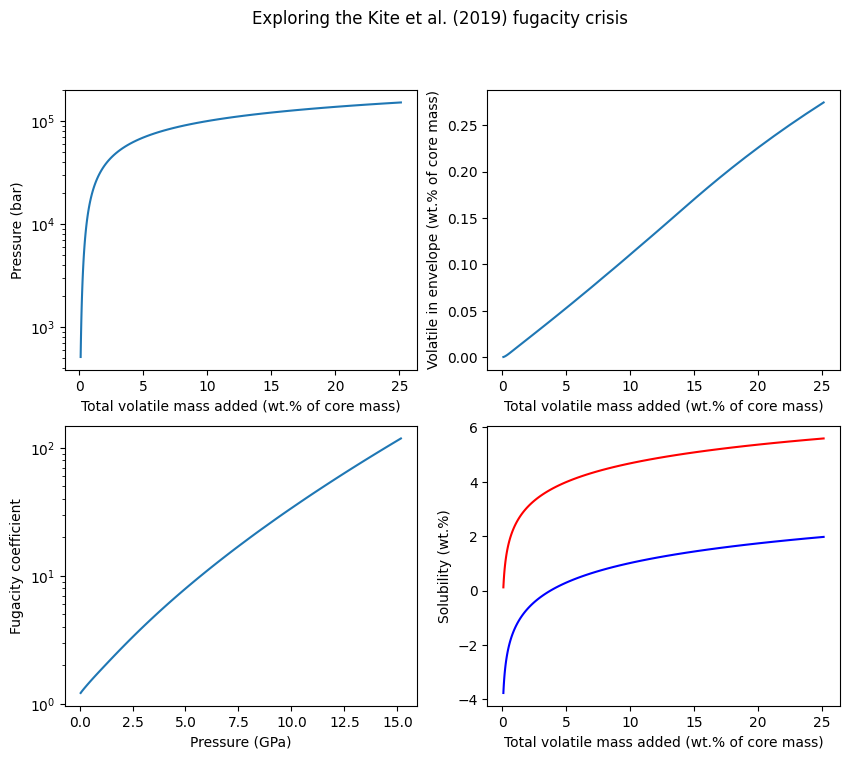

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

ax = axes[0, 0]
ax.plot(volatile_mass_added, pressure)
ax.set_yscale("log")
ax.set_xlabel(r"Total volatile mass added (wt.% of core mass)")
ax.set_ylabel("Pressure (bar)")

ax = axes[1, 0]
ax.plot(pressure_GPa, fugacity_coefficient)
ax.set_yscale("log")
ax.set_xlabel("Pressure (GPa)")
ax.set_ylabel("Fugacity coefficient")

ax = axes[1, 1]
# Plot solubility as wt.%
ax.plot(volatile_mass_added, np.log(dissolved_wtpH2), label='H2', color='blue')
ax.plot(volatile_mass_added, np.log(dissolved_wtpH2O), label='H2O', color='red')
ax.set_xlabel(r"Total volatile mass added (wt.% of core mass)")
ax.set_ylabel("Solubility (wt.%)")

ax = axes[0, 1]
y = atmosphere_mass / planet.planet_mass * 100  # type: ignore
ax.plot(volatile_mass_added, y)
ax.set_xlabel(r"Total volatile mass added (wt.% of core mass)")
ax.set_ylabel(r"Volatile in envelope (wt.% of core mass)")

fig.suptitle("Exploring the Kite et al. (2019) fugacity crisis")

plt.show()

[18:47:11 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[18:47:11 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[18:47:11 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[18:47:11 - atmodeller.classes             - INFO     ] - Attempting to solve 20 model(s)


--- Running Phase 1: Input fO2 -> Calculate O Mass ---


[18:47:33 - atmodeller.classes             - INFO     ] - Solve complete: 20 (100.00%) successful model(s)
[18:47:33 - atmodeller.classes             - INFO     ] - Solver steps (max) = 26
[18:47:33 - atmodeller.output_core         - DEBUG    ] - Creating Output
[18:47:33 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[18:47:33 - atmodeller.output_core         - INFO     ] - Computing asdict output
[18:47:35 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2
[18:47:36 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[18:47:36 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K 

--- Running Phase 2: Input O Mass -> Calculate fO2 ---


[18:47:56 - atmodeller.classes             - INFO     ] - Solve complete: 20 (100.00%) successful model(s)
[18:47:56 - atmodeller.classes             - INFO     ] - Solver steps (max) = 33
[18:47:56 - atmodeller.output_core         - DEBUG    ] - Creating Output
[18:47:56 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[18:47:56 - atmodeller.output_core         - INFO     ] - Computing asdict output
[18:47:56 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2


--- Generating Consistency Plot ---


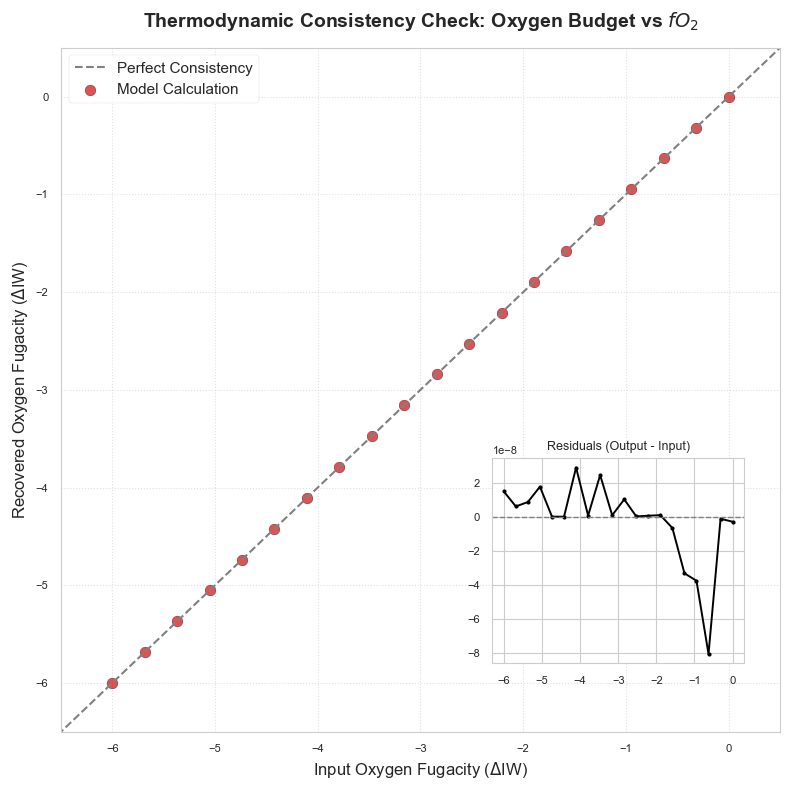

Consistency check complete. Residuals mean: 1.3844805879514866e-08


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

# --- Setup Logging & Seeds ---
logger = debug_logger()
np.random.seed(42)

# --- Configuration ---
number_of_realisations = 20  # Enough points for a smooth line
surface_temperature = 3000  # K
planet_mass = 5.154e25
surface_radius = 1.1225e7
mantle_melt_fraction = 1

# --- Species Setup ---
solubility_models = get_solubility_models()
eos_models = get_eos_models()

# Using Real Gas models as per your thesis work
H2O_rg = Species.create_gas("H2O", activity=eos_models["H2O_cork_holland98"], solubility=solubility_models["H2O_basalt_dixon95"])
H2_rg = Species.create_gas("H2", activity=eos_models["H2_chabrier21"], solubility=solubility_models["H2_basalt_hirschmann12"])
O2_rg = Species.create_gas("O2", activity=eos_models["O2_cs_shi92"]) # O2 usually has no solubility in these models, acts as redox constraint
CO_rg = Species.create_gas("CO", activity=eos_models["CO_cs_shi92"], solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_rg = Species.create_gas("CO2", activity=eos_models["CO2_cs_shi92"], solubility=solubility_models["CO2_basalt_dixon95"])
CH4_rg = Species.create_gas("CH4", activity=eos_models["CH4_cs_shi92"], solubility=solubility_models["CH4_basalt_ardia13"])

species = SpeciesCollection((H2O_rg, H2_rg, O2_rg, CO_rg, CO2_rg, CH4_rg))

# --- Planet Setup ---
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

# ==========================================
# PHASE 1: Forward Model (Fix fO2 -> Get Mass)
# ==========================================
print("--- Running Phase 1: Input fO2 -> Calculate O Mass ---")

# Range from IW-6 to IW-0
fO2_input_range = np.linspace(-6, 0, number_of_realisations)

# Fixed H and C budgets for Phase 1
log10_H_frac = -2  # 0.01% H
h_kg_input = ((10**log10_H_frac) / 100) * planet_mass
c_kg_input = h_kg_input * (10**-0.5) # C/H ratio

# Arrays to fill
calculated_O_budgets = []
calculated_H_budgets = [] # Should match input, but capturing for safety
calculated_C_budgets = []

# We run these one by one to ensure we capture exact outputs for the reverse step
# (Batching is possible but loop is clearer for logic flow)
model_forward = InteriorAtmosphere(species)

# Setup batch inputs
mass_constraints_fwd = {
    "H": np.full(number_of_realisations, h_kg_input),
    "C": np.full(number_of_realisations, c_kg_input),
}
fugacity_constraints_fwd = {O2_rg.name: IronWustiteBuffer(fO2_input_range)}

model_forward.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints_fwd,
    fugacity_constraints=fugacity_constraints_fwd,
    solver_parameters=solver_parameters,
)

# Extract the TOTAL oxygen mass calculated by the solver for each equilibrium
output_fwd = model_forward.output
dfs_fwd = output_fwd.to_dataframes()

# Extract elemental masses (Dissolved + Atmosphere)
# Note: Ensure your atmodeller version outputs 'element_O' sheet with 'total_mass'
O_masses = dfs_fwd['element_O']['total_mass'].to_numpy()
H_masses = dfs_fwd['element_H']['total_mass'].to_numpy()
C_masses = dfs_fwd['element_C']['total_mass'].to_numpy()

# ==========================================
# PHASE 2: Reverse Model (Fix Mass -> Get fO2)
# ==========================================
print("--- Running Phase 2: Input O Mass -> Calculate fO2 ---")

model_reverse = InteriorAtmosphere(species)

# Now we constrain H, C, AND O. We remove the fO2 constraint.
mass_constraints_rev = {
    "H": H_masses,
    "C": C_masses,
    "O": O_masses, 
}

# No fugacity constraints implies the system is closed and fO2 is a free variable
fugacity_constraints_rev = {} 

model_reverse.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints_rev,
    fugacity_constraints=fugacity_constraints_rev,
    solver_parameters=solver_parameters,
)

output_rev = model_reverse.output
dfs_rev = output_rev.to_dataframes()

# Extract the resulting fO2
# Usually found in O2_g sheet as 'log10dIW_P' or similar
fO2_output = dfs_rev['O2_g']['log10dIW_P'].to_numpy()

# ==========================================
# PHASE 3: Plotting Consistency
# ==========================================
print("--- Generating Consistency Plot ---")

plt.figure(figsize=(8, 8))
plt.style.use('seaborn-v0_8-paper') # Nice scientific style

# 1:1 Line
plt.plot([-7, 1], [-7, 1], color='gray', linestyle='--', linewidth=1.5, label='Perfect Consistency')

# The Data
plt.scatter(fO2_input_range, fO2_output, color='#d62728', s=60, alpha=0.8, label='Model Calculation', edgecolors='k')

# Formatting
plt.title('Thermodynamic Consistency Check: Oxygen Budget vs $fO_2$', fontsize=14, fontweight='bold', pad=15)
plt.xlabel(r'Input Oxygen Fugacity ($\Delta$IW)', fontsize=12)
plt.ylabel(r'Recovered Oxygen Fugacity ($\Delta$IW)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.xlim(-6.5, 0.5)
plt.ylim(-6.5, 0.5)

# Add residuals subplot
ax_main = plt.gca()
ax_inset = ax_main.inset_axes([0.6, 0.1, 0.35, 0.3])
residuals = fO2_output - fO2_input_range
ax_inset.plot(fO2_input_range, residuals, marker='o', markersize=3, color='black', linestyle='-')
ax_inset.set_title("Residuals (Output - Input)", fontsize=9)
ax_inset.axhline(0, color='gray', linestyle='--', linewidth=1)
ax_inset.tick_params(labelsize=8)

plt.tight_layout()
plt.savefig("consistency_check_fO2.png", dpi=300)
plt.show()

print("Consistency check complete. Residuals mean:", np.mean(np.abs(residuals)))

[18:53:24 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[18:53:24 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[18:53:24 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[18:53:24 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)


Generating Storage Capacity Plot...


[18:53:25 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[18:53:25 - atmodeller.classes             - INFO     ] - Solver steps (max) = 43
[18:53:25 - atmodeller.output_core         - DEBUG    ] - Creating Output
[18:53:25 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[18:53:25 - atmodeller.output_core         - INFO     ] - Computing asdict output
[18:53:25 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2


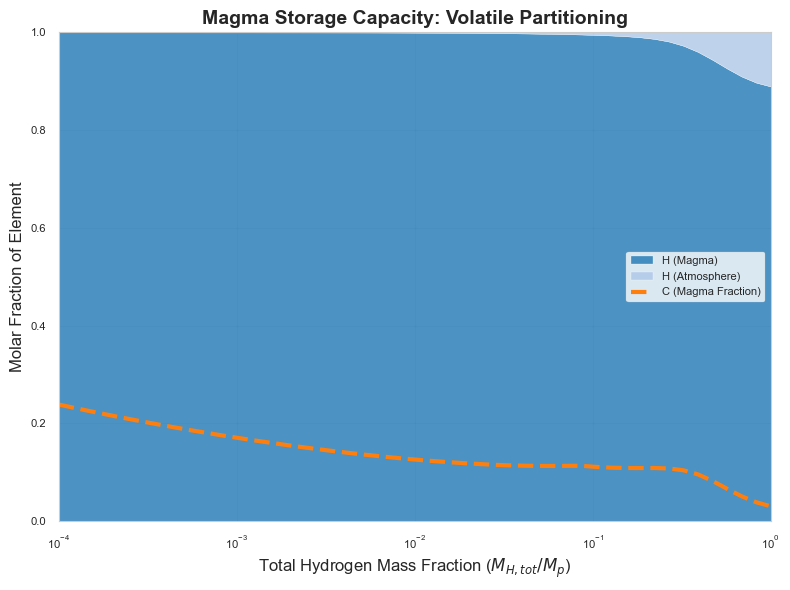

[18:53:25 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[18:53:25 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[18:53:25 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[18:53:25 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)


Generating Redox Speciation Plot...


[18:53:25 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[18:53:25 - atmodeller.classes             - INFO     ] - Solver steps (max) = 25
[18:53:25 - atmodeller.output_core         - DEBUG    ] - Creating Output
[18:53:25 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[18:53:25 - atmodeller.output_core         - INFO     ] - Computing asdict output
[18:53:26 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2


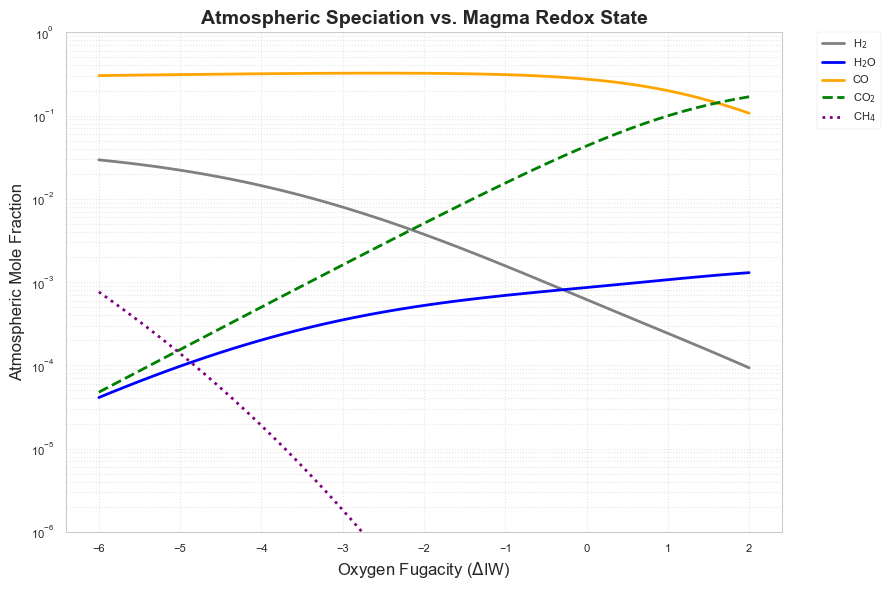

[18:53:26 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[18:53:26 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[18:53:26 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[18:53:26 - atmodeller.classes             - INFO     ] - Attempting to solve 50 model(s)


Generating Solubility Impact Plot...


[18:53:26 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[18:53:26 - atmodeller.classes             - INFO     ] - Solver steps (max) = 42
[18:53:26 - atmodeller.output_core         - DEBUG    ] - Creating Output
[18:53:27 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[18:53:27 - atmodeller.output_core         - INFO     ] - Computing asdict output
[18:53:27 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2


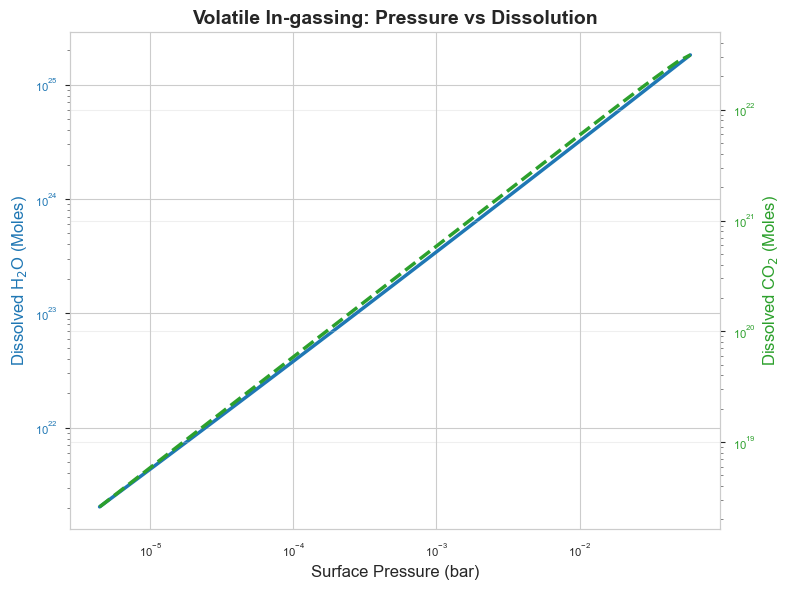

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

# Setup
logger = debug_logger()
np.random.seed(0)
plt.style.use('seaborn-v0_8-paper')

# Common Parameters
surface_temp = 3000
mass = 5.154e25
radius = 1.1225e7
melt_frac = 1.0

# Species
solubility_models = get_solubility_models()
eos_models = get_eos_models()
H2O_rg = Species.create_gas("H2O", activity=eos_models["H2O_cork_holland98"], solubility=solubility_models["H2O_basalt_dixon95"])
H2_rg = Species.create_gas("H2", activity=eos_models["H2_chabrier21"], solubility=solubility_models["H2_basalt_hirschmann12"])
O2_rg = Species.create_gas("O2", activity=eos_models["O2_cs_shi92"])
CO_rg = Species.create_gas("CO", activity=eos_models["CO_cs_shi92"], solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_rg = Species.create_gas("CO2", activity=eos_models["CO2_cs_shi92"], solubility=solubility_models["CO2_basalt_dixon95"])
CH4_rg = Species.create_gas("CH4", activity=eos_models["CH4_cs_shi92"], solubility=solubility_models["CH4_basalt_ardia13"])
species = SpeciesCollection((H2O_rg, H2_rg, O2_rg, CO_rg, CO2_rg, CH4_rg))

sub_neptune = Planet(surface_temperature=surface_temp, planet_mass=mass, surface_radius=radius, mantle_melt_fraction=melt_frac)
solver_params = SolverParameters(solver=optx.LevenbergMarquardt)

# =============================================================================
# PLOT 1: The Reservoir Effect (Storage Capacity)
# Goal: Show how magma acts as a "sponge" as we increase total volatiles
# =============================================================================
def plot_storage_capacity():
    print("Generating Storage Capacity Plot...")
    N = 50
    # Sweep Hydrogen Fraction from low (unsaturated) to high
    log10_H_frac = np.linspace(-4, 0, N) 
    fO2_fixed = np.full(N, -2.0) # Fixed at IW-2
    
    h_kg = ((10**log10_H_frac) / 100) * mass
    c_kg = h_kg * (10**-0.5) # Fixed C/H
    
    model = InteriorAtmosphere(species)
    model.solve(
        planet=sub_neptune,
        mass_constraints={"H": h_kg, "C": c_kg},
        fugacity_constraints={O2_rg.name: IronWustiteBuffer(fO2_fixed)},
        solver_parameters=solver_params
    )
    
    df = model.output.to_dataframes()
    
    # Calculate fractions
    H_tot = df['element_H']['total_moles']
    H_diss = df['element_H']['dissolved_moles']
    H_atm = df['element_H']['atmosphere_moles']
    
    C_tot = df['element_C']['total_moles']
    C_diss = df['element_C']['dissolved_moles']
    C_atm = df['element_C']['atmosphere_moles']

    # Plotting
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Stacked area for Hydrogen
    ax.stackplot(10**log10_H_frac, H_diss/H_tot, H_atm/H_tot, 
                 labels=['H (Magma)', 'H (Atmosphere)'], 
                 colors=['#1f77b4', '#aec7e8'], alpha=0.8)
    
    # Lines for Carbon (overlay)
    ax.plot(10**log10_H_frac, C_diss/C_tot, color='#ff7f0e', linewidth=3, linestyle='--', label='C (Magma Fraction)')
    
    ax.set_xscale('log')
    ax.set_xlabel('Total Hydrogen Mass Fraction ($M_{H,tot}/M_{p}$)', fontsize=12)
    ax.set_ylabel('Molar Fraction of Element', fontsize=12)
    ax.set_title('Magma Storage Capacity: Volatile Partitioning', fontsize=14, fontweight='bold')
    ax.legend(loc='center right', frameon=True)
    ax.set_xlim(10**-4, 10**0)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_storage_capacity.png", dpi=300)
    plt.show()

# =============================================================================
# PLOT 2: Redox Buffer Effects (Speciation)
# Goal: Show how fO2 changes the gas chemistry
# =============================================================================
def plot_redox_speciation():
    print("Generating Redox Speciation Plot...")
    N = 50
    fO2_sweep = np.linspace(-6, 2, N) # IW-6 to IW+2
    
    # Fixed H budget
    h_kg = np.full(N, (10**-2 / 100) * mass)
    c_kg = h_kg * (10**-0.5)
    
    model = InteriorAtmosphere(species)
    model.solve(
        planet=sub_neptune,
        mass_constraints={"H": h_kg, "C": c_kg},
        fugacity_constraints={O2_rg.name: IronWustiteBuffer(fO2_sweep)},
        solver_parameters=solver_params
    )
    
    # Extract mixing ratios (mole fractions in atmosphere)
    # Access specific species sheets
    dfs = model.output.to_dataframes()
    
    # Calculate total atmospheric moles to normalize if needed, 
    # but usually abundance/pressure is available directly or we use partial pressures
    # Here we calculate mole fractions: moles_species / total_moles_atm
    total_atm_moles = dfs['atmosphere']['species_moles'] + dfs['atmosphere']['element_moles']
    
    x_H2O = dfs['H2O_g']['atmosphere_moles'] / total_atm_moles
    x_H2 = dfs['H2_g']['atmosphere_moles'] / total_atm_moles
    x_CO2 = dfs['CO2_g']['atmosphere_moles'] / total_atm_moles
    x_CO = dfs['CO_g']['atmosphere_moles'] / total_atm_moles
    x_CH4 = dfs['CH4_g']['atmosphere_moles'] / total_atm_moles
    
    fig, ax = plt.subplots(figsize=(9, 6))
    
    ax.plot(fO2_sweep, x_H2, label='H$_2$', linewidth=2, color='grey')
    ax.plot(fO2_sweep, x_H2O, label='H$_2$O', linewidth=2, color='blue')
    ax.plot(fO2_sweep, x_CO, label='CO', linewidth=2, color='orange', linestyle='-')
    ax.plot(fO2_sweep, x_CO2, label='CO$_2$', linewidth=2, color='green', linestyle='--')
    ax.plot(fO2_sweep, x_CH4, label='CH$_4$', linewidth=2, color='purple', linestyle=':')
    
    ax.set_yscale('log')
    ax.set_xlabel(r'Oxygen Fugacity ($\Delta$IW)', fontsize=12)
    ax.set_ylabel('Atmospheric Mole Fraction', fontsize=12)
    ax.set_title('Atmospheric Speciation vs. Magma Redox State', fontsize=14, fontweight='bold')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    ax.grid(True, which='both', linestyle=':', alpha=0.5)
    ax.set_ylim(1e-6, 1.0)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_redox_speciation.png", dpi=300)
    plt.show()

# =============================================================================
# PLOT 3: Partitioning Coefficients (Solubility Impact)
# Goal: Visualize the Henry's law (or non-ideal) relationships implicitly
# =============================================================================
def plot_solubility_impact():
    print("Generating Solubility Impact Plot...")
    # Reuse the data from Plot 1, but plot partial pressure vs dissolved concentration
    N = 50
    log10_H_frac = np.linspace(-5, -1, N) 
    fO2_fixed = np.full(N, -2.0)
    
    h_kg = ((10**log10_H_frac) / 100) * mass
    c_kg = h_kg * (10**-0.5)
    
    model = InteriorAtmosphere(species)
    model.solve(
        planet=sub_neptune,
        mass_constraints={"H": h_kg, "C": c_kg},
        fugacity_constraints={O2_rg.name: IronWustiteBuffer(fO2_fixed)},
        solver_parameters=solver_params
    )
    
    dfs = model.output.to_dataframes()
    
    # H2O Partitioning
    # X: Pressure (bar) or Fugacity
    # Y: Concentration (wt ppm or mole fraction in melt)
    
    # Extracting data
    P_surf = dfs['atmosphere']['pressure'] / 1e5 # Convert Pa to bar
    
    # Calculate dissolved concentration (ppmw roughly, or just moles for now)
    # dissolved moles / mass of mantle
    # Assuming mantle mass is roughly planet mass for this viz (or constant scaling)
    H2O_diss_moles = dfs['H2O_g']['dissolved_moles']
    CO2_diss_moles = dfs['CO2_g']['dissolved_moles']
    
    fig, ax1 = plt.subplots(figsize=(8, 6))
    
    color = 'tab:blue'
    ax1.set_xlabel('Surface Pressure (bar)', fontsize=12)
    ax1.set_ylabel('Dissolved H$_2$O (Moles)', color=color, fontsize=12)
    ax1.plot(P_surf, H2O_diss_moles, color=color, linewidth=2.5)
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    
    ax2 = ax1.twinx()  
    color = 'tab:green'
    ax2.set_ylabel('Dissolved CO$_2$ (Moles)', color=color, fontsize=12)  
    ax2.plot(P_surf, CO2_diss_moles, color=color, linewidth=2.5, linestyle='--')
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_yscale('log')
    
    plt.title('Volatile In-gassing: Pressure vs Dissolution', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_solubility.png", dpi=300)
    plt.show()

if __name__ == "__main__":
    plot_storage_capacity()
    plot_redox_speciation()
    plot_solubility_impact()

<>:221: SyntaxWarning: invalid escape sequence '\D'
<>:268: SyntaxWarning: invalid escape sequence '\D'
<>:275: SyntaxWarning: invalid escape sequence '\D'
<>:282: SyntaxWarning: invalid escape sequence '\D'
<>:312: SyntaxWarning: invalid escape sequence '\D'
<>:221: SyntaxWarning: invalid escape sequence '\D'
<>:268: SyntaxWarning: invalid escape sequence '\D'
<>:275: SyntaxWarning: invalid escape sequence '\D'
<>:282: SyntaxWarning: invalid escape sequence '\D'
<>:312: SyntaxWarning: invalid escape sequence '\D'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/1984350570.py:221: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/1984350570.py:268: SyntaxWarning: invalid escape sequence '\D'
  axes[0].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/1984350570.py:275: SyntaxWarning: invalid escape sequence 

Generating Mass Variation Plot...


[19:21:58 - atmodeller.classes             - INFO     ] - Solve complete: 1 (100.00%) successful model(s)
[19:21:58 - atmodeller.classes             - INFO     ] - Solver steps (max) = 30
[19:21:58 - atmodeller.output_core         - DEBUG    ] - Creating Output
[19:21:58 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[19:21:58 - atmodeller.output_core         - INFO     ] - Computing asdict output
[19:22:01 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2
[19:22:02 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoS

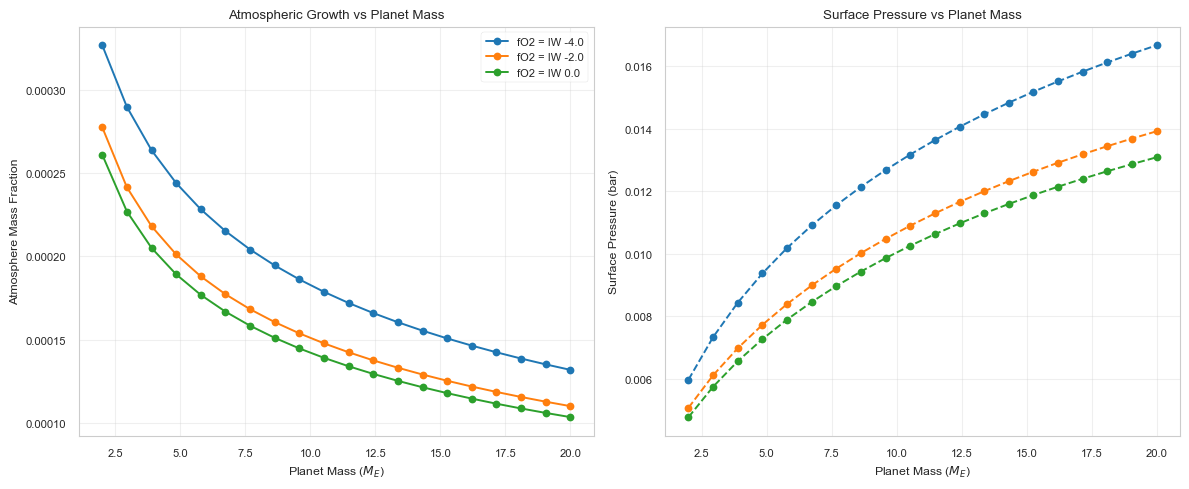

Generating Temperature-fO2 Speciation Plot...


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/1984350570.py:221: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/1984350570.py:268: SyntaxWarning: invalid escape sequence '\D'
  axes[0].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/1984350570.py:275: SyntaxWarning: invalid escape sequence '\D'
  axes[1].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/1984350570.py:282: SyntaxWarning: invalid escape sequence '\D'
  axes[2].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/1984350570.py:312: SyntaxWarning: invalid escape sequence '\D'
  ax3.set_xlabel('Oxygen Fugacity ($\Delta$IW)')


FrozenInstanceError: cannot assign to field 'surface_temperature'

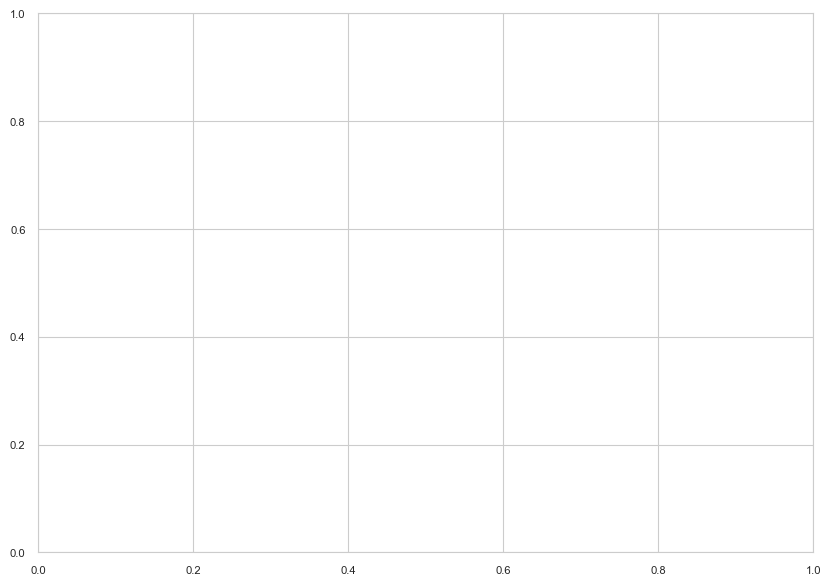

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

# Setup
logger = debug_logger()
np.random.seed(0)
plt.style.use('seaborn-v0_8-paper')

# =============================================================================
# SETUP: Species (Real Gas Models & Solubility)
# =============================================================================
eos_models = get_eos_models()
sol_models = get_solubility_models()

# --- Gases ---
# H-O System
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"], 
    solubility=sol_models["H2O_peridotite_sossi23"]
)
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
)
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
)

# Carbon System
CO2_rgs = Species.create_gas(
    "CO2", 
    activity=eos_models["CO2_cs_shi92"], 
    solubility=sol_models["CO2_basalt_dixon95"]
)
CO_rgs = Species.create_gas(
    "CO", 
    activity=eos_models["CO_cs_shi92"], 
    solubility=sol_models["CO_basalt_yoshioka19"]
)
CH4_rgs = Species.create_gas(
    "CH4", 
    activity=eos_models["CH4_cs_shi92"], 
    solubility=sol_models["CH4_basalt_ardia13"]
)

# Nitrogen & Helium System
N2_rgs = Species.create_gas(
    "N2", 
    activity=eos_models["N2_cs_saxena87"], 
    solubility=sol_models["N2_basalt_libourel03"]
)
NH3_rg = Species.create_gas(
    "NH3", 
    activity=eos_models["H3N_rk49_reid87"] # Note: H3N key
)
CHN_rg = Species.create_gas(
    "CHN", 
    activity=eos_models["CHN_rk49_reid87"]
)
He_rgs = Species.create_gas(
    "He", 
    activity=eos_models["He_chabrier21"], 
    solubility=sol_models["He_basalt_jambon86"]
)

# Collection (No Condensates)
species = SpeciesCollection((
    H2O_rgs, H2_rgs, O2_rg, 
    CO2_rgs, CO_rgs, CH4_rgs, 
    N2_rgs, NH3_rg, CHN_rg, 
    He_rgs
))

solver_params = SolverParameters(solver=optx.LevenbergMarquardt)

# =============================================================================
# CONSTANTS & RELATIONS
# =============================================================================
ME = 5.972e24
RE = 6.371e6

# Lodders et al. (2009) Solar Abundances (wt%)
H_masspercent_lodders09 = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09 = 0.22
N_masspercent_lodders09 = 0.07
O_masspercent_lodders09 = 0.63

# Ratios relative to Hydrogen mass
C_H_RATIO = C_masspercent_lodders09 / H_masspercent_lodders09
N_H_RATIO = N_masspercent_lodders09 / H_masspercent_lodders09
He_H_RATIO = He_masspercent_lodders09 / H_masspercent_lodders09

def get_radius_from_mass(mass_kg):
    """Mass-Radius relationship: R ~ M^0.29"""
    m_earth_units = mass_kg / ME
    r_earth_units = 1.03 * (m_earth_units ** 0.29)
    return r_earth_units * RE

def get_solar_like_budget(h_kg):
    """Returns dictionary of element masses scaling with Hydrogen based on Lodders 09"""
    return {
        "H": h_kg,
        "C": h_kg * C_H_RATIO,
        "N": h_kg * N_H_RATIO,
        "He": h_kg * He_H_RATIO
    }

# =============================================================================
# PLOT 1: Mass Variation with fO2 Overlays
# =============================================================================
def plot_mass_variation():
    print("Generating Mass Variation Plot...")
    N = 20
    masses = np.linspace(2, 20, N) * ME 
    
    fO2_cases = [-4.0, -2.0, 0.0] 
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    for fO2, color in zip(fO2_cases, colors):
        atm_masses = []
        pressures = []
        
        for m in masses:
            r = get_radius_from_mass(m)
            p = Planet(surface_temperature=3000, planet_mass=m, surface_radius=r, mantle_melt_fraction=1.0)
            
            # 0.05% H wt% of planet mass, scaled solar
            h_kg = (0.05 / 100) * m
            mass_constraints = get_solar_like_budget(h_kg)
            
            model = InteriorAtmosphere(species)
            model.solve(
                planet=p,
                mass_constraints=mass_constraints,
                fugacity_constraints={O2_rg.name: IronWustiteBuffer(np.array([fO2]))},
                solver_parameters=solver_params
            )
            
            df = model.output.to_dataframes()
            atm_masses.append(df['atmosphere']['mass'].item() / m) 
            pressures.append(df['atmosphere']['pressure'].item() / 1e5) 

        ax1.plot(masses/ME, atm_masses, 'o-', color=color, label=f'fO2 = IW {fO2}')
        ax2.plot(masses/ME, pressures, 'o--', color=color, label=f'fO2 = IW {fO2}')

    ax1.set_xlabel('Planet Mass ($M_E$)')
    ax1.set_ylabel('Atmosphere Mass Fraction')
    ax1.set_title('Atmospheric Growth vs Planet Mass')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.set_xlabel('Planet Mass ($M_E$)')
    ax2.set_ylabel('Surface Pressure (bar)')
    ax2.set_title('Surface Pressure vs Planet Mass')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_mass_variation.png", dpi=300)
    plt.show()

# =============================================================================
# PLOT 2: Temperature Effects with fO2 (Speciation)
# =============================================================================
def plot_temperature_fO2_speciation():
    print("Generating Temperature-fO2 Speciation Plot...")
    N = 40
    fO2_sweep = np.linspace(-6, 2, N)
    temps = [2000, 3000, 4000]
    styles = [':', '-', '--']
    
    p_fixed = Planet(surface_temperature=3000, planet_mass=5.15e25, surface_radius=1.12e7, mantle_melt_fraction=1.0)
    
    # Fixed budget: 1e21 kg H (~0.002% of mass), solar ratios
    mass_constraints = get_solar_like_budget(1e21)

    fig, ax = plt.subplots(figsize=(10, 7))
    
    for T, style in zip(temps, styles):
        p_fixed.surface_temperature = T
        
        model = InteriorAtmosphere(species)
        model.solve(
            planet=p_fixed,
            mass_constraints=mass_constraints,
            fugacity_constraints={O2_rg.name: IronWustiteBuffer(fO2_sweep)},
            solver_parameters=solver_params
        )
        
        dfs = model.output.to_dataframes()
        total_moles = dfs['atmosphere']['moles']
        
        x_H2O = dfs['H2O_g']['atmosphere_moles'] / total_moles
        x_CH4 = dfs['CH4_g']['atmosphere_moles'] / total_moles
        x_NH3 = dfs['NH3_g']['atmosphere_moles'] / total_moles
        
        ax.plot(fO2_sweep, x_H2O, color='blue', linestyle=style, linewidth=2, label=f'H2O ({T}K)' if fO2_sweep[0]==-6 else "")
        ax.plot(fO2_sweep, x_CH4, color='orange', linestyle=style, linewidth=2, label=f'CH4 ({T}K)' if fO2_sweep[0]==-6 else "")
        ax.plot(fO2_sweep, x_NH3, color='purple', linestyle=style, linewidth=2, label=f'NH3 ({T}K)' if fO2_sweep[0]==-6 else "")

    ax.set_yscale('log')
    ax.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    ax.set_ylabel('Atmospheric Mole Fraction')
    ax.set_title('Speciation Sensitivity to Temperature and Redox')
    ax.legend(loc='best')
    ax.grid(True, which='both', alpha=0.3)
    ax.set_ylim(1e-5, 1.0)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_temp_fO2.png", dpi=300)
    plt.show()

# =============================================================================
# PLOT 3: Detailed Volatile Partitioning (Per Volatile)
# =============================================================================
def plot_detailed_partitioning_and_budget():
    print("Generating Detailed Partitioning Plots...")
    N = 50
    fO2_sweep = np.linspace(-6, 2, N)
    
    p_fixed = Planet(surface_temperature=3000, planet_mass=5.15e25, surface_radius=1.12e7, mantle_melt_fraction=1.0)
    
    # Higher volatile budget for partitioning calc
    mass_constraints = get_solar_like_budget(5e21)
    
    model = InteriorAtmosphere(species)
    model.solve(
        planet=p_fixed,
        mass_constraints=mass_constraints,
        fugacity_constraints={O2_rg.name: IronWustiteBuffer(fO2_sweep)},
        solver_parameters=solver_params
    )
    
    df = model.output.to_dataframes()
    
    # Calculate Mass Fractions (Atmosphere / Total)
    H_atm_frac = df['element_H']['atmosphere_mass'] / df['element_H']['total_mass']
    C_atm_frac = df['element_C']['atmosphere_mass'] / df['element_C']['total_mass']
    N_atm_frac = df['element_N']['atmosphere_mass'] / df['element_N']['total_mass']
    
    # --- Partitioning Plot (Per Volatile) ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Hydrogen
    axes[0].fill_between(fO2_sweep, 0, H_atm_frac, color='#aec7e8', alpha=0.7, label='Atmosphere')
    axes[0].fill_between(fO2_sweep, H_atm_frac, 1, color='#1f77b4', alpha=0.7, label='Magma')
    axes[0].set_title('Hydrogen Partitioning')
    axes[0].set_ylabel('Mass Fraction')
    axes[0].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    axes[0].grid(True, alpha=0.3)
    
    # Carbon
    axes[1].fill_between(fO2_sweep, 0, C_atm_frac, color='#ffbb78', alpha=0.7, label='Atmosphere')
    axes[1].fill_between(fO2_sweep, C_atm_frac, 1, color='#ff7f0e', alpha=0.7, label='Magma')
    axes[1].set_title('Carbon Partitioning')
    axes[1].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    axes[1].grid(True, alpha=0.3)

    # Nitrogen
    axes[2].fill_between(fO2_sweep, 0, N_atm_frac, color='#98df8a', alpha=0.7, label='Atmosphere')
    axes[2].fill_between(fO2_sweep, N_atm_frac, 1, color='#2ca02c', alpha=0.7, label='Magma')
    axes[2].set_title('Nitrogen Partitioning')
    axes[2].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    axes[2].legend(loc='center right')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_partitioning_separate.png", dpi=300)
    plt.show()
    
    # --- Molecular Budget Stack (Total) ---
    H_tot_moles = df['element_H']['total_moles']
    
    mol_H2 = df['H2_g']['atmosphere_moles'] * 2
    mol_H2O = df['H2O_g']['atmosphere_moles'] * 2
    mol_CH4 = df['CH4_g']['atmosphere_moles'] * 4
    mol_NH3 = df['NH3_g']['atmosphere_moles'] * 3
    mol_CHN = df['CHN_g']['atmosphere_moles'] * 1
    mol_diss = df['element_H']['dissolved_moles']
    
    fig2, ax3 = plt.subplots(figsize=(8, 6))
    ax3.stackplot(fO2_sweep, 
                  mol_H2/H_tot_moles, 
                  mol_H2O/H_tot_moles, 
                  mol_CH4/H_tot_moles,
                  mol_NH3/H_tot_moles,
                  mol_CHN/H_tot_moles,
                  mol_diss/H_tot_moles,
                  labels=['H$_2$', 'H$_2$O', 'CH$_4$', 'NH$_3$', 'CHN', 'Dissolved H'],
                  colors=['grey', 'blue', 'orange', 'purple', 'brown', 'red'], alpha=0.8)
    
    ax3.set_title('Total Hydrogen Molecular Budget vs Redox')
    ax3.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    ax3.set_ylabel('Fraction of Total Hydrogen Inventory')
    ax3.legend(loc='upper left', bbox_to_anchor=(1,1))
    ax3.set_xlim(fO2_sweep.min(), fO2_sweep.max())
    ax3.set_ylim(0, 1)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_molecular_budget.png", dpi=300)
    plt.show()

if __name__ == "__main__":
    plot_mass_variation()
    plot_temperature_fO2_speciation()
    plot_detailed_partitioning_and_budget()

<>:227: SyntaxWarning: invalid escape sequence '\D'
<>:274: SyntaxWarning: invalid escape sequence '\D'
<>:281: SyntaxWarning: invalid escape sequence '\D'
<>:288: SyntaxWarning: invalid escape sequence '\D'
<>:318: SyntaxWarning: invalid escape sequence '\D'
<>:227: SyntaxWarning: invalid escape sequence '\D'
<>:274: SyntaxWarning: invalid escape sequence '\D'
<>:281: SyntaxWarning: invalid escape sequence '\D'
<>:288: SyntaxWarning: invalid escape sequence '\D'
<>:318: SyntaxWarning: invalid escape sequence '\D'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/3978194804.py:227: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/3978194804.py:274: SyntaxWarning: invalid escape sequence '\D'
  axes[0].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/3978194804.py:281: SyntaxWarning: invalid escape sequence 

Generating Mass Variation Plot...


[19:27:37 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2
[19:27:37 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[19:27:37 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[19:27:37 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0

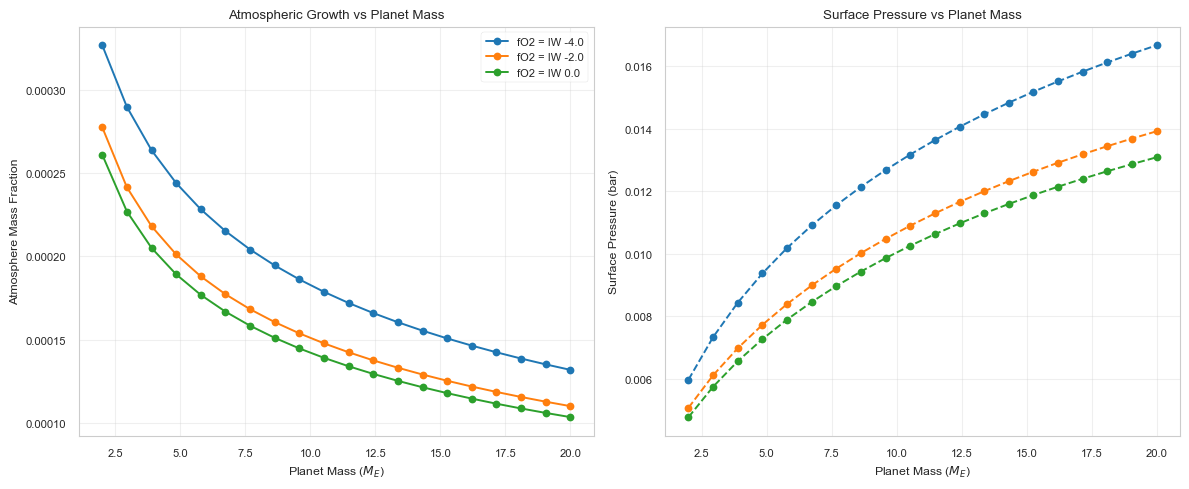

[19:28:17 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[19:28:17 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[19:28:17 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[19:28:17 - atmodeller.classes             - IN

Generating Temperature-fO2 Speciation Plot...


[19:28:56 - atmodeller.classes             - INFO     ] - Solve complete: 40 (100.00%) successful model(s)
[19:28:56 - atmodeller.classes             - INFO     ] - Solver steps (max) = 51
[19:28:56 - atmodeller.output_core         - DEBUG    ] - Creating Output
[19:28:56 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[19:28:56 - atmodeller.output_core         - INFO     ] - Computing asdict output
[19:28:59 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/3978194804.py:227: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/3978194804.py:274: SyntaxWarning: invalid escape sequence '\D'
  axes[0].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/3978194804.py:281: SyntaxWarning: inv

KeyError: 'moles'

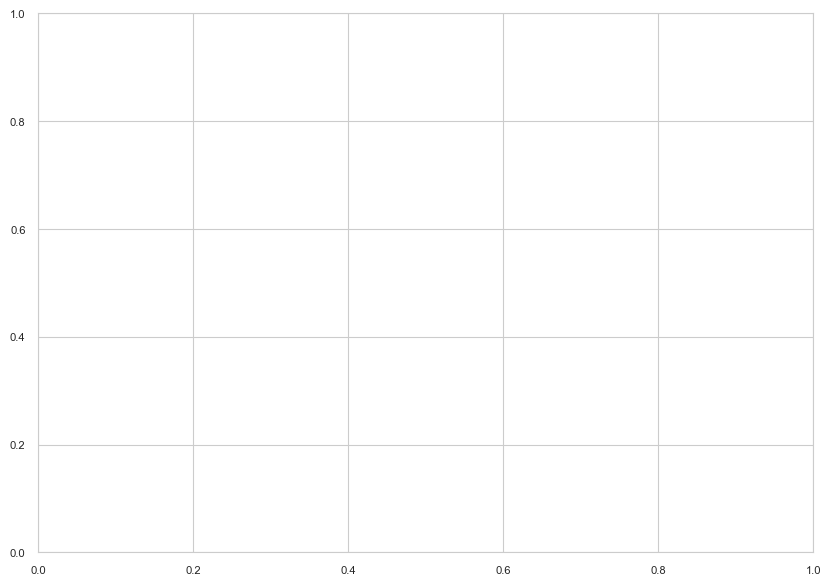

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models, IdealGas
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

# Setup
logger = debug_logger()
np.random.seed(0)
plt.style.use('seaborn-v0_8-paper')

# =============================================================================
# SETUP: Species (Real Gas Models & Solubility)
# =============================================================================
eos_models = get_eos_models()
sol_models = get_solubility_models()

# --- Gases ---
# H-O System
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"], 
    solubility=sol_models["H2O_peridotite_sossi23"]
)
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
)
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
)

# Carbon System
CO2_rgs = Species.create_gas(
    "CO2", 
    activity=eos_models["CO2_cs_shi92"], 
    solubility=sol_models["CO2_basalt_dixon95"]
)
CO_rgs = Species.create_gas(
    "CO", 
    activity=eos_models["CO_cs_shi92"], 
    solubility=sol_models["CO_basalt_yoshioka19"]
)
CH4_rgs = Species.create_gas(
    "CH4", 
    activity=eos_models["CH4_cs_shi92"], 
    solubility=sol_models["CH4_basalt_ardia13"]
)

# Nitrogen & Helium System
# Fixed: Ensure valid activity models exist or fallback to IdealGas()
N2_rgs = Species.create_gas(
    "N2", 
    activity=eos_models.get("N2_cs_saxena87", IdealGas()), 
    solubility=sol_models["N2_basalt_libourel03"]
)
NH3_rg = Species.create_gas(
    "NH3", 
    activity=eos_models.get("H3N_rk49_reid87", IdealGas()) 
)
CHN_rg = Species.create_gas(
    "CHN", 
    activity=eos_models.get("CHN_rk49_reid87", IdealGas())
)
He_rgs = Species.create_gas(
    "He", 
    activity=eos_models["He_chabrier21"], 
    solubility=sol_models["He_basalt_jambon86"]
)

# Collection
species = SpeciesCollection((
    H2O_rgs, H2_rgs, O2_rg, 
    CO2_rgs, CO_rgs, CH4_rgs, 
    N2_rgs, NH3_rg, CHN_rg, 
    He_rgs
))

solver_params = SolverParameters(solver=optx.LevenbergMarquardt)

# =============================================================================
# CONSTANTS & RELATIONS
# =============================================================================
ME = 5.972e24
RE = 6.371e6

# Lodders et al. (2009) Solar Abundances (wt%)
H_masspercent_lodders09 = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09 = 0.22
N_masspercent_lodders09 = 0.07
O_masspercent_lodders09 = 0.63

# Ratios relative to Hydrogen mass
C_H_RATIO = C_masspercent_lodders09 / H_masspercent_lodders09
N_H_RATIO = N_masspercent_lodders09 / H_masspercent_lodders09
He_H_RATIO = He_masspercent_lodders09 / H_masspercent_lodders09

def get_radius_from_mass(mass_kg):
    """Mass-Radius relationship: R ~ M^0.29"""
    m_earth_units = mass_kg / ME
    r_earth_units = 1.03 * (m_earth_units ** 0.29)
    return r_earth_units * RE

def get_solar_like_budget(h_kg):
    """Returns dictionary of element masses scaling with Hydrogen based on Lodders 09"""
    return {
        "H": h_kg,
        "C": h_kg * C_H_RATIO,
        "N": h_kg * N_H_RATIO,
        "He": h_kg * He_H_RATIO
    }

# =============================================================================
# PLOT 1: Mass Variation with fO2 Overlays
# =============================================================================
def plot_mass_variation():
    print("Generating Mass Variation Plot...")
    N = 20
    masses = np.linspace(2, 20, N) * ME 
    
    fO2_cases = [-4.0, -2.0, 0.0] 
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    for fO2, color in zip(fO2_cases, colors):
        atm_masses = []
        pressures = []
        
        for m in masses:
            r = get_radius_from_mass(m)
            p = Planet(surface_temperature=3000, planet_mass=m, surface_radius=r, mantle_melt_fraction=1.0)
            
            # 0.05% H wt% of planet mass, scaled solar
            h_kg = (0.05 / 100) * m
            mass_constraints = get_solar_like_budget(h_kg)
            
            model = InteriorAtmosphere(species)
            model.solve(
                planet=p,
                mass_constraints=mass_constraints,
                fugacity_constraints={O2_rg.name: IronWustiteBuffer(np.array([fO2]))},
                solver_parameters=solver_params
            )
            
            df = model.output.to_dataframes()
            atm_masses.append(df['atmosphere']['mass'].item() / m) 
            pressures.append(df['atmosphere']['pressure'].item() / 1e5) 

        ax1.plot(masses/ME, atm_masses, 'o-', color=color, label=f'fO2 = IW {fO2}')
        ax2.plot(masses/ME, pressures, 'o--', color=color, label=f'fO2 = IW {fO2}')

    ax1.set_xlabel('Planet Mass ($M_E$)')
    ax1.set_ylabel('Atmosphere Mass Fraction')
    ax1.set_title('Atmospheric Growth vs Planet Mass')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.set_xlabel('Planet Mass ($M_E$)')
    ax2.set_ylabel('Surface Pressure (bar)')
    ax2.set_title('Surface Pressure vs Planet Mass')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_mass_variation.png", dpi=300)
    plt.show()



<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:93: SyntaxWarning: invalid escape sequence '\D'
<>:100: SyntaxWarning: invalid escape sequence '\D'
<>:107: SyntaxWarning: invalid escape sequence '\D'
<>:137: SyntaxWarning: invalid escape sequence '\D'
<>:46: SyntaxWarning: invalid escape sequence '\D'
<>:93: SyntaxWarning: invalid escape sequence '\D'
<>:100: SyntaxWarning: invalid escape sequence '\D'
<>:107: SyntaxWarning: invalid escape sequence '\D'
<>:137: SyntaxWarning: invalid escape sequence '\D'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/4039378633.py:46: SyntaxWarning: invalid escape sequence '\D'
  ax.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/4039378633.py:93: SyntaxWarning: invalid escape sequence '\D'
  axes[0].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_28695/4039378633.py:100: SyntaxWarning: invalid escape sequence '\D'
 

Generating Temperature-fO2 Speciation Plot...


[19:33:13 - atmodeller.classes             - INFO     ] - Solve complete: 40 (100.00%) successful model(s)
[19:33:13 - atmodeller.classes             - INFO     ] - Solver steps (max) = 51
[19:33:13 - atmodeller.output_core         - DEBUG    ] - Creating Output
[19:33:13 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[19:33:13 - atmodeller.output_core         - INFO     ] - Computing asdict output
[19:33:15 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2
[19:33:16 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, No

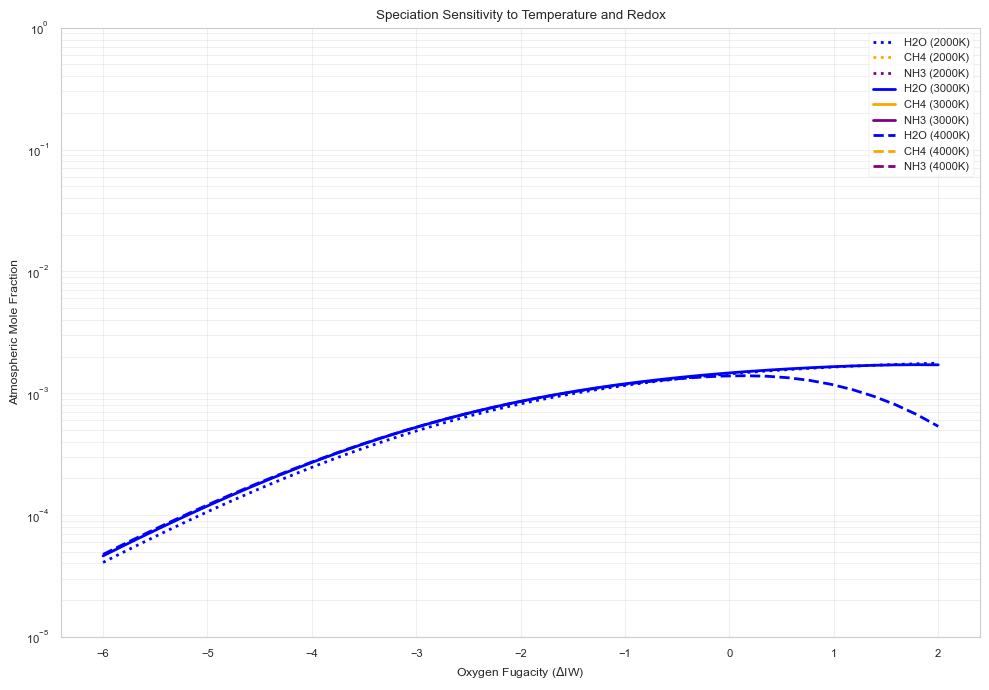

[19:33:21 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[19:33:21 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[19:33:21 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[19:33:21 - atmodeller.classes             - IN

Generating Detailed Partitioning Plots...


[19:33:23 - atmodeller.classes             - INFO     ] - Solve complete: 50 (100.00%) successful model(s)
[19:33:23 - atmodeller.classes             - INFO     ] - Solver steps (max) = 49
[19:33:23 - atmodeller.output_core         - DEBUG    ] - Creating Output
[19:33:23 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[19:33:23 - atmodeller.output_core         - INFO     ] - Computing asdict output
[19:33:24 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2


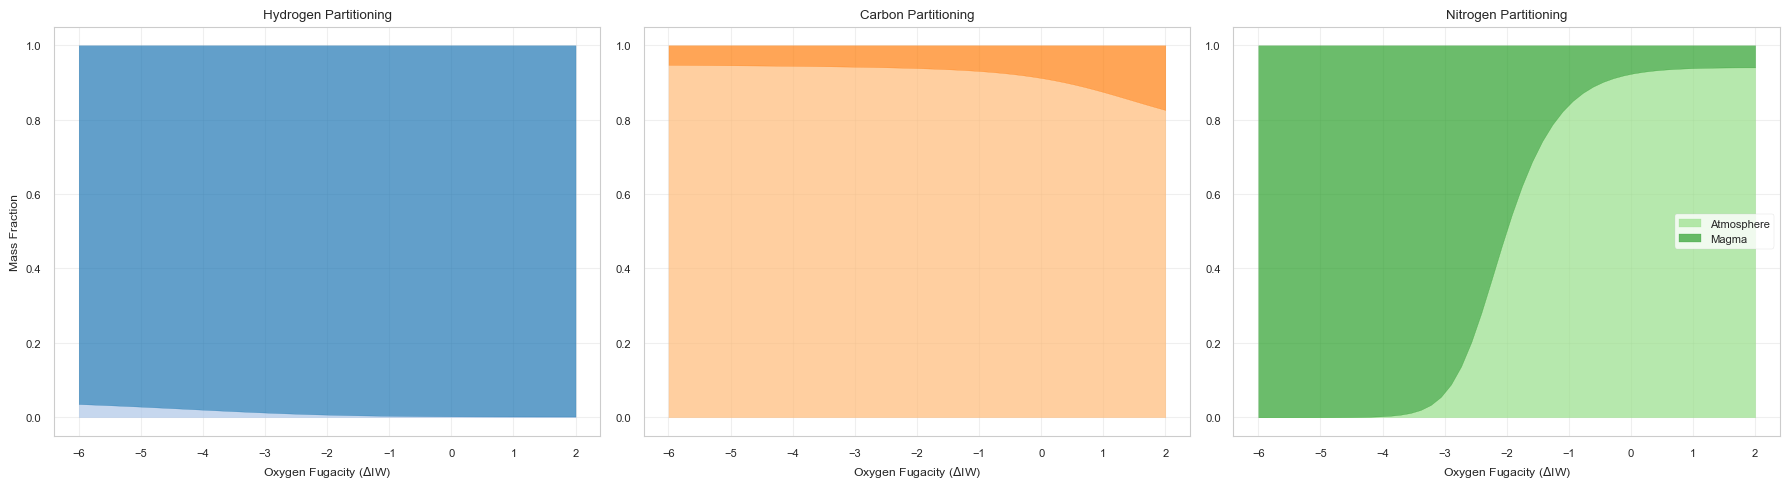

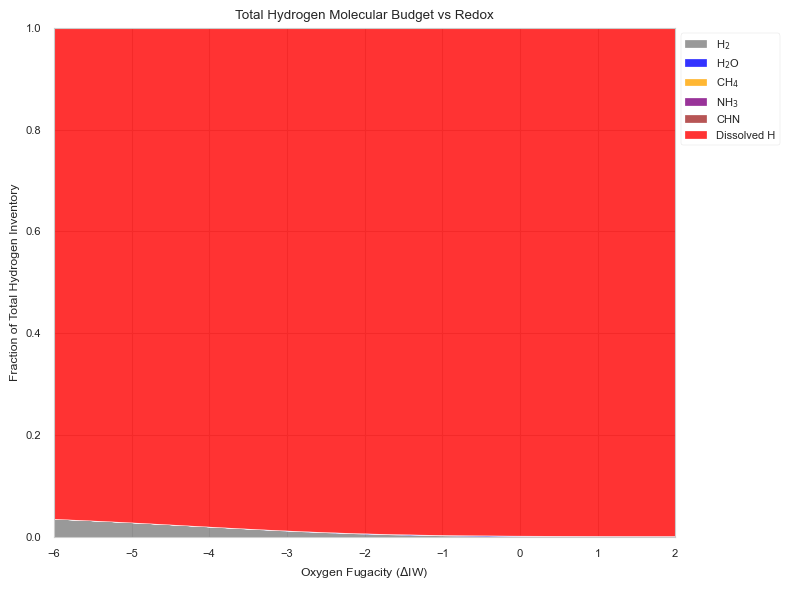

In [22]:
# =============================================================================
# PLOT 2: Temperature Effects with fO2 (Speciation)
# =============================================================================
def plot_temperature_fO2_speciation():
    print("Generating Temperature-fO2 Speciation Plot...")
    N = 40
    fO2_sweep = np.linspace(-6, 2, N)
    temps = [2000, 3000, 4000]
    styles = [':', '-', '--']
    
    # Fixed budget: 1e21 kg H (~0.002% of mass), solar ratios
    mass_constraints = get_solar_like_budget(1e21)

    fig, ax = plt.subplots(figsize=(10, 7))
    
    for T, style in zip(temps, styles):
        # FIX: Create a NEW planet instance for each temperature step
        # Do not modify p_fixed.surface_temperature in place
        p_temp = Planet(
            surface_temperature=T, 
            planet_mass=5.15e25, 
            surface_radius=1.12e7, 
            mantle_melt_fraction=1.0
        )
        
        model = InteriorAtmosphere(species)
        model.solve(
            planet=p_temp,
            mass_constraints=mass_constraints,
            fugacity_constraints={O2_rg.name: IronWustiteBuffer(fO2_sweep)},
            solver_parameters=solver_params
        )
        
        dfs = model.output.to_dataframes()
        total_moles = dfs['atmosphere']['element_moles'] + dfs['atmosphere']['species_moles']
        
        x_H2O = dfs['H2O_g']['atmosphere_moles'] / total_moles
        x_CH4 = dfs['CH4_g']['atmosphere_moles'] / total_moles
        x_NH3 = dfs['H3N_g']['atmosphere_moles'] / total_moles
        
        ax.plot(fO2_sweep, x_H2O, color='blue', linestyle=style, linewidth=2, label=f'H2O ({T}K)' if fO2_sweep[0]==-6 else "")
        ax.plot(fO2_sweep, x_CH4, color='orange', linestyle=style, linewidth=2, label=f'CH4 ({T}K)' if fO2_sweep[0]==-6 else "")
        ax.plot(fO2_sweep, x_NH3, color='purple', linestyle=style, linewidth=2, label=f'NH3 ({T}K)' if fO2_sweep[0]==-6 else "")

    ax.set_yscale('log')
    ax.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    ax.set_ylabel('Atmospheric Mole Fraction')
    ax.set_title('Speciation Sensitivity to Temperature and Redox')
    ax.legend(loc='best')
    ax.grid(True, which='both', alpha=0.3)
    ax.set_ylim(1e-5, 1.0)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_temp_fO2.png", dpi=300)
    plt.show()

# =============================================================================
# PLOT 3: Detailed Volatile Partitioning (Per Volatile)
# =============================================================================
def plot_detailed_partitioning_and_budget():
    print("Generating Detailed Partitioning Plots...")
    N = 50
    fO2_sweep = np.linspace(-6, 2, N)
    
    p_fixed = Planet(surface_temperature=3000, planet_mass=5.15e25, surface_radius=1.12e7, mantle_melt_fraction=1.0)
    
    # Higher volatile budget for partitioning calc
    mass_constraints = get_solar_like_budget(5e21)
    
    model = InteriorAtmosphere(species)
    model.solve(
        planet=p_fixed,
        mass_constraints=mass_constraints,
        fugacity_constraints={O2_rg.name: IronWustiteBuffer(fO2_sweep)},
        solver_parameters=solver_params
    )
    
    df = model.output.to_dataframes()
    
    # Calculate Mass Fractions (Atmosphere / Total)
    H_atm_frac = df['element_H']['atmosphere_mass'] / df['element_H']['total_mass']
    C_atm_frac = df['element_C']['atmosphere_mass'] / df['element_C']['total_mass']
    N_atm_frac = df['element_N']['atmosphere_mass'] / df['element_N']['total_mass']
    
    # --- Partitioning Plot (Per Volatile) ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Hydrogen
    axes[0].fill_between(fO2_sweep, 0, H_atm_frac, color='#aec7e8', alpha=0.7, label='Atmosphere')
    axes[0].fill_between(fO2_sweep, H_atm_frac, 1, color='#1f77b4', alpha=0.7, label='Magma')
    axes[0].set_title('Hydrogen Partitioning')
    axes[0].set_ylabel('Mass Fraction')
    axes[0].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    axes[0].grid(True, alpha=0.3)
    
    # Carbon
    axes[1].fill_between(fO2_sweep, 0, C_atm_frac, color='#ffbb78', alpha=0.7, label='Atmosphere')
    axes[1].fill_between(fO2_sweep, C_atm_frac, 1, color='#ff7f0e', alpha=0.7, label='Magma')
    axes[1].set_title('Carbon Partitioning')
    axes[1].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    axes[1].grid(True, alpha=0.3)

    # Nitrogen
    axes[2].fill_between(fO2_sweep, 0, N_atm_frac, color='#98df8a', alpha=0.7, label='Atmosphere')
    axes[2].fill_between(fO2_sweep, N_atm_frac, 1, color='#2ca02c', alpha=0.7, label='Magma')
    axes[2].set_title('Nitrogen Partitioning')
    axes[2].set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    axes[2].legend(loc='center right')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_partitioning_separate.png", dpi=300)
    plt.show()
    
    # --- Molecular Budget Stack (Total) ---
    H_tot_moles = df['element_H']['total_moles']
    
    mol_H2 = df['H2_g']['atmosphere_moles'] * 2
    mol_H2O = df['H2O_g']['atmosphere_moles'] * 2
    mol_CH4 = df['CH4_g']['atmosphere_moles'] * 4
    mol_NH3 = df['H3N_g']['atmosphere_moles'] * 3
    mol_CHN = df['CHN_g']['atmosphere_moles'] * 1
    mol_diss = df['element_H']['dissolved_moles']
    
    fig2, ax3 = plt.subplots(figsize=(8, 6))
    ax3.stackplot(fO2_sweep, 
                  mol_H2/H_tot_moles, 
                  mol_H2O/H_tot_moles, 
                  mol_CH4/H_tot_moles,
                  mol_NH3/H_tot_moles,
                  mol_CHN/H_tot_moles,
                  mol_diss/H_tot_moles,
                  labels=['H$_2$', 'H$_2$O', 'CH$_4$', 'NH$_3$', 'CHN', 'Dissolved H'],
                  colors=['grey', 'blue', 'orange', 'purple', 'brown', 'red'], alpha=0.8)
    
    ax3.set_title('Total Hydrogen Molecular Budget vs Redox')
    ax3.set_xlabel('Oxygen Fugacity ($\Delta$IW)')
    ax3.set_ylabel('Fraction of Total Hydrogen Inventory')
    ax3.legend(loc='upper left', bbox_to_anchor=(1,1))
    ax3.set_xlim(fO2_sweep.min(), fO2_sweep.max())
    ax3.set_ylim(0, 1)
    
    plt.tight_layout()
    plt.savefig("thesis_plot_molecular_budget.png", dpi=300)
    plt.show()

if __name__ == "__main__":
    plot_temperature_fO2_speciation()
    plot_detailed_partitioning_and_budget()

<>:207: SyntaxWarning: invalid escape sequence '\D'
<>:207: SyntaxWarning: invalid escape sequence '\D'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_29942/3992551540.py:207: SyntaxWarning: invalid escape sequence '\D'
  ax_inset.set_title("Residuals ($\Delta$log$fO_2$)", fontsize=9)
[20:47:22 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[20:47:22 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[20:47:22 - atmodeller.classes             - INFO     ] - rea

--- Running Phase 1: Input fO2 -> Calculate Equilibrium ---


[20:47:23 - atmodeller.classes             - INFO     ] - Solve complete: 20 (100.00%) successful model(s)
[20:47:23 - atmodeller.classes             - INFO     ] - Solver steps (max) = 75
[20:47:23 - atmodeller.output_core         - DEBUG    ] - Creating Output
[20:47:23 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[20:47:23 - atmodeller.output_core         - INFO     ] - Computing asdict output
[20:47:24 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2
[20:47:24 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, No


=== Phase 1 Results Table (First 5 rows) ===
   Input fO2 (dIW)  Total H Mass (kg)  Total C Mass (kg)  Total N Mass (kg)  \
0        -6.000000       5.154000e+23       1.534344e+21       4.882003e+20   
1        -5.684211       5.154000e+23       1.534344e+21       4.882003e+20   
2        -5.368421       5.154000e+23       1.534344e+21       4.882003e+20   
3        -5.052632       5.154000e+23       1.534344e+21       4.882003e+20   
4        -4.736842       5.154000e+23       1.534344e+21       4.882003e+20   

   Total He Mass (kg)  Calculated O Mass (kg)  Surface Pressure (bar)  \
0        1.721952e+23            3.453949e+23                0.438824   
1        1.721952e+23            4.085165e+23                0.434410   
2        1.721952e+23            4.820559e+23                0.429338   
3        1.721952e+23            5.673443e+23                0.423554   
4        1.721952e+23            6.657556e+23                0.417017   

   Atmosphere Mass (kg)  
0          2.5

[20:47:25 - atmodeller.classes             - INFO     ] - Solve complete: 20 (100.00%) successful model(s)
[20:47:25 - atmodeller.classes             - INFO     ] - Solver steps (max) = 84
[20:47:25 - atmodeller.output_core         - DEBUG    ] - Creating Output
[20:47:25 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[20:47:25 - atmodeller.output_core         - INFO     ] - Computing asdict output
[20:47:26 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2


--- Generating Consistency Plot ---


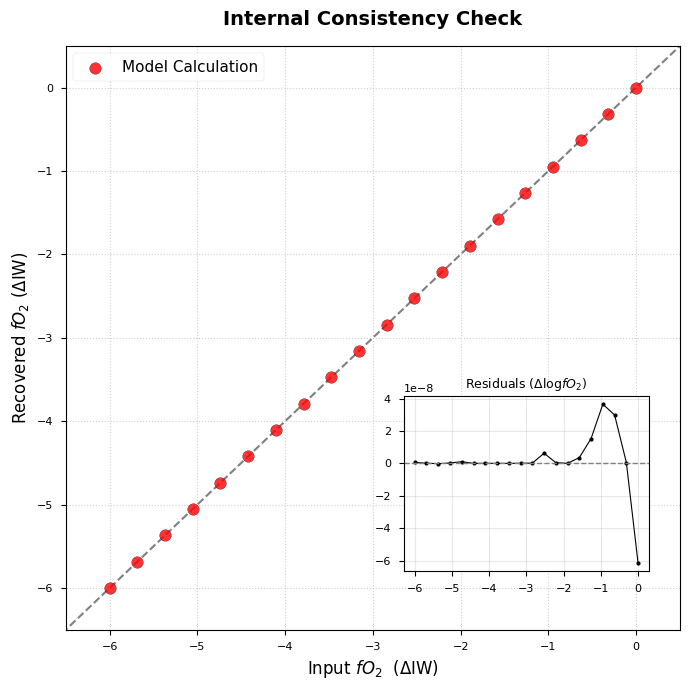

Mean Absolute Residual: 7.88e-09 log units


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models, IdealGas
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

# --- Setup Logging & Seeds ---
logger = debug_logger()
np.random.seed(42)

# --- Configuration ---
number_of_realisations = 20  
surface_temperature = 3000  # K
planet_mass = 5.154e25
surface_radius = 1.1225e7
mantle_melt_fraction = 1

# =============================================================================
# SPECIES SETUP (Aligned with user definitions)
# =============================================================================
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Helper to safely get model or fallback to IdealGas
def get_eos(key):
    return eos_models.get(key, IdealGas())

# C-H-O System
H2O_rgs = Species.create_gas("H2O", activity=get_eos("H2O_cork_holland98"), solubility=sol_models["H2O_peridotite_sossi23"])
H2_rgs = Species.create_gas("H2", activity=get_eos("H2_chabrier21"), solubility=sol_models["H2_basalt_hirschmann12"])
O2_rg = Species.create_gas("O2", activity=get_eos("O2_cs_shi92"))
CO2_rgs = Species.create_gas("CO2", activity=get_eos("CO2_cs_shi92"), solubility=sol_models["CO2_basalt_dixon95"])
CO_rgs = Species.create_gas("CO", activity=get_eos("CO_cs_shi92"), solubility=sol_models["CO_basalt_yoshioka19"])
CH4_rgs = Species.create_gas("CH4", activity=get_eos("CH4_cs_shi92"), solubility=sol_models["CH4_basalt_ardia13"])

# N-He System (New Elements)
N2_rgs = Species.create_gas(
    "N2", 
    activity=get_eos("N2_cs_saxena87"), 
    solubility=sol_models["N2_basalt_libourel03"]
)
# Note: Using "H3N" as requested in snippet
NH3_rg = Species.create_gas("NH3", activity=get_eos("H3N_rk49_reid87")) 
CHN_rg = Species.create_gas("CHN", activity=get_eos("CHN_rk49_reid87"))
He_rgs = Species.create_gas(
    "He", 
    activity=get_eos("He_chabrier21"), 
    solubility=sol_models["He_basalt_jambon86"]
)

# Full Collection
species = SpeciesCollection((
    H2O_rgs, H2_rgs, O2_rg, 
    CO2_rgs, CO_rgs, CH4_rgs, 
    N2_rgs, NH3_rg, CHN_rg, 
    He_rgs
))

# --- Planet Setup ---
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

# Lodders 2009 Ratios (wt%)
H_masspercent = 73.9
He_masspercent = 24.69
C_masspercent = 0.22
N_masspercent = 0.07

# =============================================================================
# PHASE 1: Forward Model (Input fO2 -> Calculate O Mass)
# =============================================================================
print("--- Running Phase 1: Input fO2 -> Calculate Equilibrium ---")

fO2_input_range = np.linspace(-6, 0, number_of_realisations)

# Fixed budgets (1% H atmosphere assumption for scaling)
h_kg_input = (1.0 / 100) * planet_mass
c_kg_input = h_kg_input * (C_masspercent / H_masspercent)
n_kg_input = h_kg_input * (N_masspercent / H_masspercent)
he_kg_input = h_kg_input * (He_masspercent / H_masspercent)

model_forward = InteriorAtmosphere(species)

mass_constraints_fwd = {
    "H": np.full(number_of_realisations, h_kg_input),
    "C": np.full(number_of_realisations, c_kg_input),
    "N": np.full(number_of_realisations, n_kg_input),
    "He": np.full(number_of_realisations, he_kg_input),
}
fugacity_constraints_fwd = {O2_rg.name: IronWustiteBuffer(fO2_input_range)}

model_forward.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints_fwd,
    fugacity_constraints=fugacity_constraints_fwd,
    solver_parameters=solver_parameters,
)

output_fwd = model_forward.output
dfs_fwd = output_fwd.to_dataframes()

# --- EXTRACT DATA FOR TABLE ---
# Getting total masses calculated by the solver (including the O mass required to satisfy fO2)
O_masses = dfs_fwd['element_O']['total_mass'].to_numpy()
H_masses = dfs_fwd['element_H']['total_mass'].to_numpy()
C_masses = dfs_fwd['element_C']['total_mass'].to_numpy()
N_masses = dfs_fwd['element_N']['total_mass'].to_numpy()
He_masses = dfs_fwd['element_He']['total_mass'].to_numpy()
pressures = dfs_fwd['atmosphere']['pressure'].to_numpy() / 1e5 # bar
atm_mass = dfs_fwd['atmosphere']['mass'].to_numpy()

# Create DataFrame
results_table = pd.DataFrame({
    "Input fO2 (dIW)": fO2_input_range,
    "Total H Mass (kg)": H_masses,
    "Total C Mass (kg)": C_masses,
    "Total N Mass (kg)": N_masses,
    "Total He Mass (kg)": He_masses,
    "Calculated O Mass (kg)": O_masses,
    "Surface Pressure (bar)": pressures,
    "Atmosphere Mass (kg)": atm_mass
})

# Save Table
results_table.to_csv("phase1_consistency_table.csv", index=False)
print("\n=== Phase 1 Results Table (First 5 rows) ===")
print(results_table.head())
print("Full table saved to 'phase1_consistency_table.csv'\n")

# =============================================================================
# PHASE 2: Reverse Model (Input Calculated Masses -> Recover fO2)
# =============================================================================
print("--- Running Phase 2: Input Calculated Masses -> Recover fO2 ---")

model_reverse = InteriorAtmosphere(species)

# Constrain EVERYTHING including the Oxygen mass we just found
mass_constraints_rev = {
    "H": H_masses,
    "C": C_masses,
    "N": N_masses,
    "He": He_masses,
    "O": O_masses, 
}

# No fugacity constraints -> Closed system solution
fugacity_constraints_rev = {} 

model_reverse.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints_rev,
    fugacity_constraints=fugacity_constraints_rev,
    solver_parameters=solver_parameters,
)

output_rev = model_reverse.output
dfs_rev = output_rev.to_dataframes()

# Recovered fO2
fO2_output = dfs_rev['O2_g']['log10dIW_P'].to_numpy()

# =============================================================================
# PHASE 3: Plotting
# =============================================================================
print("--- Generating Consistency Plot ---")

plt.figure(figsize=(7, 7))
plt.style.use('seaborn-v0_8-paper') 

# 1:1 Line
plt.plot([-7, 1], [-7, 1], color='gray', linestyle='--', linewidth=1.5, label='')

# Data Points
plt.scatter(fO2_input_range, fO2_output, color='red', s=70, alpha=0.8, 
            label='Model Calculation', edgecolors='k', zorder=3)

plt.title('Internal Consistency Check', fontsize=14, fontweight='bold', pad=15)
plt.xlabel(r'Input $fO_2$  ($\Delta$IW)', fontsize=12)
plt.ylabel(r'Recovered $fO_2$ ($\Delta$IW)', fontsize=12)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.xlim(-6.5, 0.5)
plt.ylim(-6.5, 0.5)

# Residuals Inset
ax_main = plt.gca()
ax_inset = ax_main.inset_axes([0.55, 0.1, 0.4, 0.3])
residuals = fO2_output - fO2_input_range
ax_inset.plot(fO2_input_range, residuals, marker='o', markersize=3, color='black', linestyle='-', linewidth=0.8)
ax_inset.set_title("Residuals ($\Delta$log$fO_2$)", fontsize=9)
ax_inset.axhline(0, color='gray', linestyle='--', linewidth=1)
ax_inset.tick_params(labelsize=8)
ax_inset.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("consistency_check_full_system.png", dpi=300)
plt.show()

print(f"Mean Absolute Residual: {np.mean(np.abs(residuals)):.2e} log units")

<>:207: SyntaxWarning: invalid escape sequence '\D'
<>:207: SyntaxWarning: invalid escape sequence '\D'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_35441/1915605756.py:207: SyntaxWarning: invalid escape sequence '\D'
  ax_inset.set_title("Residuals ($\Delta$log$fO_2$)", fontsize=9)
[17:55:50 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[17:55:50 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[17:55:50 - atmodeller.classes             - INFO     ] - rea

--- Running Phase 1: Input fO2 -> Calculate Equilibrium ---


[17:56:29 - atmodeller.classes             - INFO     ] - Solve complete: 30 (100.00%) successful model(s)
[17:56:29 - atmodeller.classes             - INFO     ] - Solver steps (max) = 114
[17:56:29 - atmodeller.output_core         - DEBUG    ] - Creating Output
[17:56:29 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[17:56:29 - atmodeller.output_core         - INFO     ] - Computing asdict output
[17:56:32 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2
[17:56:34 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, N


=== Phase 1 Results Table (First 5 rows) ===
   Input fO2 (dIW)  Total H Mass (kg)  Total C Mass (kg)  Total N Mass (kg)  \
0        -6.000000       5.154000e+23       1.534344e+23       4.882003e+22   
1        -5.586207       5.154000e+23       1.534344e+23       4.882003e+22   
2        -5.172414       5.154000e+23       1.534344e+23       4.882003e+22   
3        -4.758621       5.154000e+23       1.534344e+23       4.882003e+22   
4        -4.344828       5.154000e+23       1.534344e+23       4.882003e+22   

   Total He Mass (kg)  Calculated O Mass (kg)  Surface Pressure (bar)  \
0        1.721952e+23            3.943112e+23            54379.661505   
1        1.721952e+23            4.888793e+23            53840.110951   
2        1.721952e+23            6.029400e+23            53239.334780   
3        1.721952e+23            7.390764e+23            52619.235637   
4        1.721952e+23            8.992093e+23            52007.098691   

   Atmosphere Mass (kg)  
0          3.1

[17:57:15 - atmodeller.classes             - INFO     ] - Solve complete: 30 (100.00%) successful model(s)
[17:57:15 - atmodeller.classes             - INFO     ] - Solver steps (max) = 185
[17:57:15 - atmodeller.output_core         - DEBUG    ] - Creating Output
[17:57:15 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[17:57:15 - atmodeller.output_core         - INFO     ] - Computing asdict output
[17:57:15 - atmodeller.output_core         - DEBUG    ] - Found O2_g so back-computing log10 shift for fO2


--- Generating Consistency Plot ---


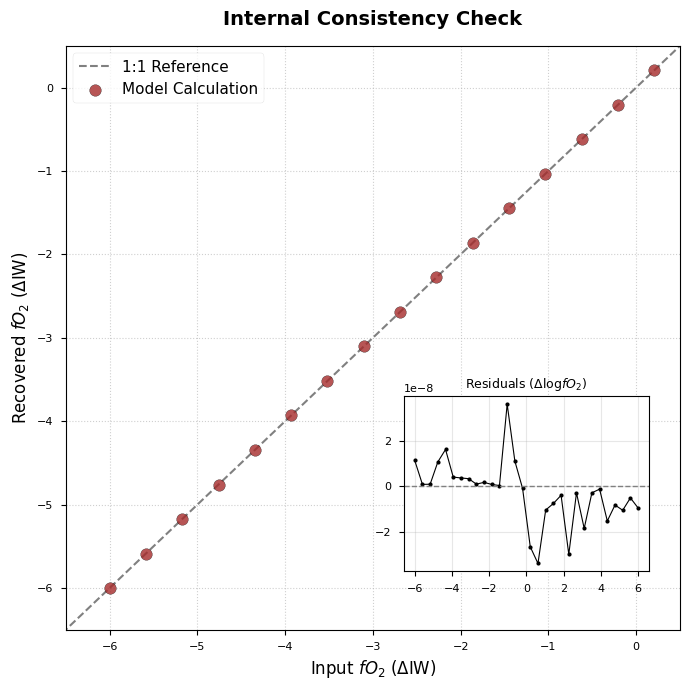

Mean Absolute Residual: 9.71e-09 log units


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optimistix as optx
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models, IdealGas
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

# --- Setup Logging & Seeds ---
logger = debug_logger()
np.random.seed(42)

# --- Configuration ---
number_of_realisations = 30  
surface_temperature = 3000  # K
planet_mass = 5.154e25
surface_radius = 1.1225e7
mantle_melt_fraction = 1

# =============================================================================
# SPECIES SETUP (Aligned with user definitions)
# =============================================================================
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Helper to safely get model or fallback to IdealGas
def get_eos(key):
    return eos_models.get(key, IdealGas())

# C-H-O System
H2O_rgs = Species.create_gas("H2O", activity=get_eos("H2O_cork_holland98"), solubility=sol_models["H2O_peridotite_sossi23"])
H2_rgs = Species.create_gas("H2", activity=get_eos("H2_chabrier21"), solubility=sol_models["H2_basalt_hirschmann12"])
O2_rg = Species.create_gas("O2", activity=get_eos("O2_cs_shi92"))
CO2_rgs = Species.create_gas("CO2", activity=get_eos("CO2_cs_shi92"), solubility=sol_models["CO2_basalt_dixon95"])
CO_rgs = Species.create_gas("CO", activity=get_eos("CO_cs_shi92"), solubility=sol_models["CO_basalt_yoshioka19"])
CH4_rgs = Species.create_gas("CH4", activity=get_eos("CH4_cs_shi92"), solubility=sol_models["CH4_basalt_ardia13"])

# N-He System (New Elements)
N2_rgs = Species.create_gas(
    "N2", 
    activity=get_eos("N2_cs_saxena87"), 
    solubility=sol_models["N2_basalt_libourel03"]
)
# Note: Using "H3N" as requested in snippet
NH3_rg = Species.create_gas("H3N", activity=get_eos("H3N_rk49_reid87")) 
CHN_rg = Species.create_gas("CHN", activity=get_eos("CHN_rk49_reid87"))
He_rgs = Species.create_gas(
    "He", 
    activity=get_eos("He_chabrier21"), 
    solubility=sol_models["He_basalt_jambon86"]
)

# Full Collection
species = SpeciesCollection((
    H2O_rgs, H2_rgs, O2_rg, 
    CO2_rgs, CO_rgs, CH4_rgs, 
    N2_rgs, NH3_rg, CHN_rg, 
    He_rgs
))

# --- Planet Setup ---
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

# Lodders 2009 Ratios (wt%)
H_masspercent = 73.9
He_masspercent = 24.69
C_masspercent = 0.22
N_masspercent = 0.07

# =============================================================================
# PHASE 1: Forward Model (Input fO2 -> Calculate O Mass)
# =============================================================================
print("--- Running Phase 1: Input fO2 -> Calculate Equilibrium ---")

fO2_input_range = np.linspace(-6, 6, number_of_realisations)

# Fixed budgets (1% H atmosphere assumption for scaling)
h_kg_input = (1.0 / 100) * planet_mass
c_kg_input = h_kg_input * (C_masspercent / H_masspercent) * 100
n_kg_input = h_kg_input * (N_masspercent / H_masspercent) * 100
he_kg_input = h_kg_input * (He_masspercent / H_masspercent)

model_forward = InteriorAtmosphere(species)

mass_constraints_fwd = {
    "H": np.full(number_of_realisations, h_kg_input),
    "C": np.full(number_of_realisations, c_kg_input),
    "N": np.full(number_of_realisations, n_kg_input),
    "He": np.full(number_of_realisations, he_kg_input),
}
fugacity_constraints_fwd = {O2_rg.name: IronWustiteBuffer(fO2_input_range)}

model_forward.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints_fwd,
    fugacity_constraints=fugacity_constraints_fwd,
    solver_parameters=solver_parameters,
)

output_fwd = model_forward.output
dfs_fwd = output_fwd.to_dataframes()

# --- EXTRACT DATA FOR TABLE ---
# Getting total masses calculated by the solver (including the O mass required to satisfy fO2)
O_masses = dfs_fwd['element_O']['total_mass'].to_numpy()
H_masses = dfs_fwd['element_H']['total_mass'].to_numpy()
C_masses = dfs_fwd['element_C']['total_mass'].to_numpy()
N_masses = dfs_fwd['element_N']['total_mass'].to_numpy()
He_masses = dfs_fwd['element_He']['total_mass'].to_numpy()
pressures = dfs_fwd['atmosphere']['pressure'].to_numpy()
atm_mass = dfs_fwd['atmosphere']['mass'].to_numpy()

# Create DataFrame
results_table = pd.DataFrame({
    "Input fO2 (dIW)": fO2_input_range,
    "Total H Mass (kg)": H_masses,
    "Total C Mass (kg)": C_masses,
    "Total N Mass (kg)": N_masses,
    "Total He Mass (kg)": He_masses,
    "Calculated O Mass (kg)": O_masses,
    "Surface Pressure (bar)": pressures,
    "Atmosphere Mass (kg)": atm_mass
})

# Save Table
results_table.to_csv("phase1_consistency_table.csv", index=False)
print("\n=== Phase 1 Results Table (First 5 rows) ===")
print(results_table.head())
print("Full table saved to 'phase1_consistency_table.csv'\n")

# =============================================================================
# PHASE 2: Reverse Model (Input Calculated Masses -> Recover fO2)
# =============================================================================
print("--- Running Phase 2: Input Calculated Masses -> Recover fO2 ---")

model_reverse = InteriorAtmosphere(species)

# Constrain EVERYTHING including the Oxygen mass we just found
mass_constraints_rev = {
    "H": H_masses,
    "C": C_masses,
    "N": N_masses,
    "He": He_masses,
    "O": O_masses, 
}

# No fugacity constraints -> Closed system solution
fugacity_constraints_rev = {} 

model_reverse.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints_rev,
    fugacity_constraints=fugacity_constraints_rev,
    solver_parameters=solver_parameters,
)

output_rev = model_reverse.output
dfs_rev = output_rev.to_dataframes()

# Recovered fO2
fO2_output = dfs_rev['O2_g']['log10dIW_P'].to_numpy()

# =============================================================================
# PHASE 3: Plotting
# =============================================================================
print("--- Generating Consistency Plot ---")

plt.figure(figsize=(7, 7))
plt.style.use('seaborn-v0_8-paper') 

# 1:1 Reference Line
plt.plot([-7, 1], [-7, 1], color='gray', linestyle='--', linewidth=1.5, label='1:1 Reference')

# Data Points - Brownish Red
plt.scatter(fO2_input_range, fO2_output, color='#A52A2A', s=70, alpha=0.8, 
            label='Model Calculation', edgecolors='k', zorder=3)

plt.title('Internal Consistency Check', fontsize=14, fontweight='bold', pad=15)
plt.xlabel(r'Input $fO_2$ ($\Delta$IW)', fontsize=12)
plt.ylabel(r'Recovered $fO_2$ ($\Delta$IW)', fontsize=12)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.xlim(-6.5, 0.5)
plt.ylim(-6.5, 0.5)

# Residuals Inset
ax_main = plt.gca()
ax_inset = ax_main.inset_axes([0.55, 0.1, 0.4, 0.3])
residuals = fO2_output - fO2_input_range
ax_inset.plot(fO2_input_range, residuals, marker='o', markersize=3, color='black', linestyle='-', linewidth=0.8)
ax_inset.set_title("Residuals ($\Delta$log$fO_2$)", fontsize=9)
ax_inset.axhline(0, color='gray', linestyle='--', linewidth=1)
ax_inset.tick_params(labelsize=8)
ax_inset.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("consistency_check_full_system.png", dpi=300)
plt.show()

print(f"Mean Absolute Residual: {np.mean(np.abs(residuals)):.2e} log units")

--- Generating Consistency Plot ---


<>:90: SyntaxWarning: invalid escape sequence '\D'
<>:90: SyntaxWarning: invalid escape sequence '\D'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_35441/503621015.py:90: SyntaxWarning: invalid escape sequence '\D'
  ax_inset.set_title("Residuals ($\Delta$log$fO_2$)", fontsize=9)


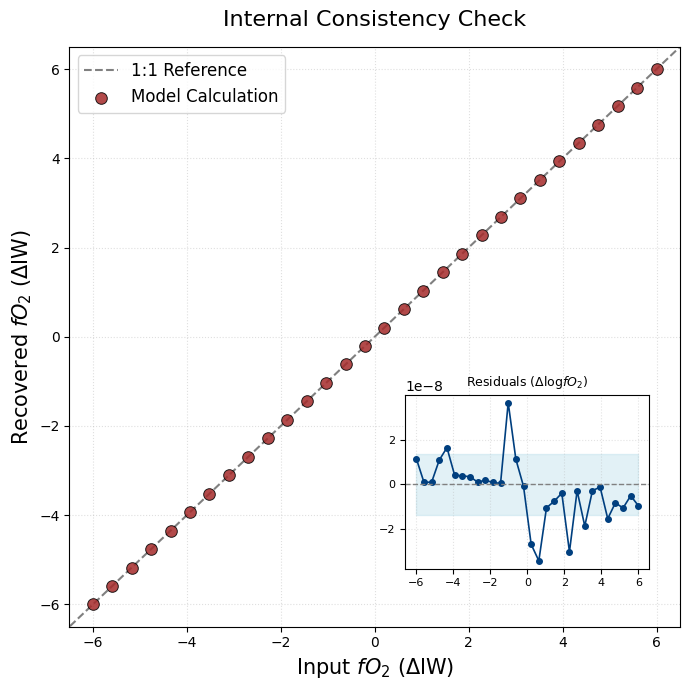

Mean Absolute Residual: 9.71e-09 log units


In [12]:
print("--- Generating Consistency Plot ---")

# ---------------------------
# Apply custom style
# ---------------------------
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 16
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

set_style()


# ---------------------------
# Main figure
# ---------------------------
plt.figure(figsize=(7, 7))

# 1:1 Reference Line
plt.plot(
    [-7, 7], [-7, 7],
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="1:1 Reference"
)

# Data Points
plt.scatter(
    fO2_input_range, fO2_output,
    color="#A52A2A",
    s=70,
    alpha=0.85,
    label="Model Calculation",
    edgecolors="black",
    linewidth=0.7,
    zorder=3
)

plt.title("Internal Consistency Check", pad=15)
plt.xlabel(r"Input $fO_2$ ($\Delta$IW)")
plt.ylabel(r"Recovered $fO_2$ ($\Delta$IW)")
plt.legend(loc="upper left")

plt.xlim(-6.5, 6.5)
plt.ylim(-6.5, 6.5)


# ---------------------------
# Residuals Calculation
# ---------------------------
residuals = fO2_output - fO2_input_range
sigma = np.std(residuals)


# ---------------------------
# Residuals Inset (y-axis auto!)
# ---------------------------
ax_main = plt.gca()
ax_inset = ax_main.inset_axes([0.55, 0.1, 0.4, 0.3])

# Shaded ±1σ band
ax_inset.fill_between(
    fO2_input_range,
    -sigma, sigma,
    color="lightblue",
    alpha=0.35
)

# Residual curve
ax_inset.plot(
    fO2_input_range,
    residuals,
    marker="o",
    markersize=4,
    color="#003f7f",
    linestyle="-",
    linewidth=1.2
)

# Zero line
ax_inset.axhline(0, color="gray", linestyle="--", linewidth=1)

# Title only
ax_inset.set_title("Residuals ($\Delta$log$fO_2$)", fontsize=9)

# Y-axis: AUTO — no manual ticks, no label
# ax_inset.set_yticks(...)  <-- removed
# ax_inset.set_ylabel(...)  <-- removed

# X ticks still matching main plot
ax_inset.set_xticks(np.arange(-6, 7, 2))

ax_inset.tick_params(labelsize=8)
ax_inset.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig("consistency_check_full_system.png", dpi=300)
plt.show()

print(f"Mean Absolute Residual: {np.mean(np.abs(residuals)):.2e} log units")
